# 04_modelo_final: modelo elegido, prueba única y análisis de errores
**Persona A.** Este notebook (1) reentrena el modelo elegido con el entrenamiento, (2) guarda el Pipeline en `models/pipeline_final.joblib`, (3) lo evalúa **una sola vez** en la prueba oficial y (4) analiza los errores.

> **Regla:** el conjunto de prueba se evalúa en una única ejecución de la sección 4. No cambies la configuración después de ver esos números. Si algo falla antes de esa sección, corrige y continúa; si ya viste los resultados de prueba, no vuelvas a elegir modelo.

**Decisión tomada antes de ver la prueba:** Random Forest con la configuración encontrada por el algoritmo genético (03_optimizacion_ga), entrenado con **todo** el entrenamiento sin duplicados. Justificación: en validación cruzada las tres configuraciones de RF quedaron empatadas dentro del ruido (F1 ≈ 0,925); se elige la de menor costo de inferencia.

## 0. Configuración y reproducibilidad

In [1]:
import sys, os, json, time, platform, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve, classification_report)
warnings.filterwarnings("ignore")

# --- AJUSTA ESTAS RUTAS ---
RUTA_TRAIN_ORIGINAL = "UNSW_NB15_testing-set.csv"    # 175 341 filas = ENTRENAMIENTO oficial (los nombres vienen cruzados en la fuente)
RUTA_TEST_ORIGINAL  = "UNSW_NB15_training-set.csv"   # 82 332 filas  = PRUEBA oficial
RUTA_SRC     = "."          # carpeta con preprocesamiento.py (en el repo: "../src")
DIR_MODELOS  = "models"     # en el repo: "../models"
DIR_REPORTES = "reports"    # en el repo: "../reports"

USAR_ENTRENAMIENTO_COMPLETO = True   # True: todo el entrenamiento sin duplicados. False: submuestra de 25 000 (como en 02 y 03)
N_SUBMUESTRA = 25000

# Configuración elegida (mejor del algoritmo genético, 03_optimizacion_ga)
CONFIG_FINAL = {"n_estimators": 150, "max_depth": 20, "min_samples_leaf": 1, "max_features": 0.3}

sys.path.insert(0, RUTA_SRC)
import preprocesamiento as pp
SEED = pp.SEED
np.random.seed(SEED)
os.makedirs(DIR_MODELOS, exist_ok=True); os.makedirs(DIR_REPORTES, exist_ok=True)
print("Python", platform.python_version(), "| sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__, "| joblib", joblib.__version__)
print("CPU núcleos:", os.cpu_count(), "| semilla:", SEED)

Python 3.13.18 | sklearn 1.6.1 | pandas 2.2.3 | numpy 2.1.3 | joblib 1.6.0
CPU núcleos: 2 | semilla: 42


## 1. Datos

In [2]:
train, test = pp.cargar_datos(RUTA_TRAIN_ORIGINAL, RUTA_TEST_ORIGINAL)
assert len(train) == 175341 and len(test) == 82332, "Rutas invertidas o archivos distintos: revisa RUTA_TRAIN_ORIGINAL y RUTA_TEST_ORIGINAL"

train = pp.eliminar_duplicados(train)                    # solo en entrenamiento; la prueba se deja intacta
if not USAR_ENTRENAMIENTO_COMPLETO:
    train = pp.submuestra_estratificada(train, N_SUBMUESTRA, col_estrato="attack_cat", semilla=SEED)

X_tr, y_tr, _        = pp.separar_xy(train)
X_te, y_te, cat_te   = pp.separar_xy(test)
print("Entrenamiento:", X_tr.shape, "| % ataque:", round(y_tr.mean()*100, 1))
print("Prueba       :", X_te.shape, "| % ataque:", round(y_te.mean()*100, 1))

Entrenamiento: (101269, 42) | % ataque: 48.8
Prueba       : (82332, 42) | % ataque: 55.1


## 2. Pipeline final y reentrenamiento (solo con entrenamiento)

In [3]:
num_cols, cat_cols = pp.columnas_por_tipo(X_tr, excluir=pp.COLUMNAS_REDUNDANTES)
cols_log = pp.detectar_columnas_log(X_tr, num_cols)
preprocesador = pp.construir_preprocesador(num_cols, cat_cols, cols_log)

pipeline_final = Pipeline([
    ("pre", preprocesador),
    ("modelo", RandomForestClassifier(**CONFIG_FINAL, n_jobs=-1, random_state=SEED)),
])
t0 = time.perf_counter()
pipeline_final.fit(X_tr, y_tr)
t_fit = time.perf_counter() - t0
print(f"Entrenado en {t_fit:.1f} s | {len(num_cols)} numéricas, {len(cat_cols)} categóricas, {len(cols_log)} con log1p")

Entrenado en 79.2 s | 38 numéricas, 3 categóricas, 29 con log1p


## 3. Guardar el Pipeline (antes de mirar la prueba)

In [4]:
RUTA_JOBLIB = f"{DIR_MODELOS}/pipeline_final.joblib"
joblib.dump(pipeline_final, RUTA_JOBLIB, compress=3)   # comprimido: pesa menos y se carga igual con joblib.load

meta = {"modelo": "RandomForestClassifier", "hiperparametros": CONFIG_FINAL, "semilla": SEED,
        "entrenamiento_registros": int(len(X_tr)), "entrenamiento_completo": USAR_ENTRENAMIENTO_COMPLETO,
        "columnas_entrada": list(X_tr.columns), "columnas_categoricas": cat_cols,
        "sklearn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
        "python": platform.python_version()}
with open(f"{DIR_MODELOS}/pipeline_final_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

# Comprobación: se recarga y predice un registro nuevo (lo que hará el prototipo)
recargado = joblib.load(RUTA_JOBLIB)
una_fila = X_te.iloc[[0]]
print("Predicción de un registro:", int(recargado.predict(una_fila)[0]),
      "| P(ataque) =", round(float(recargado.predict_proba(una_fila)[0, 1]), 3))
print("Tamaño del archivo (MB):", round(os.path.getsize(RUTA_JOBLIB)/1e6, 1))

Predicción de un registro: 1 | P(ataque) = 0.784
Tamaño del archivo (MB): 13.6


## 4. Evaluación en prueba: **UNA SOLA VEZ**
Ejecuta esta celda una vez. Estos números son los que van al informe.

In [5]:
t0 = time.perf_counter()
pred  = pipeline_final.predict(X_te)
t_inf = time.perf_counter() - t0
proba = pipeline_final.predict_proba(X_te)[:, 1]

m = confusion_matrix(y_te, pred, labels=[0, 1]); tn, fp, fn, tp = m.ravel()
resultados_prueba = {
    "F1 (ataque)": f1_score(y_te, pred), "Precisión": precision_score(y_te, pred),
    "Recall": recall_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, proba),
    "Exactitud": accuracy_score(y_te, pred),
    "Falsos negativos": int(fn), "Falsos positivos": int(fp),
    "Inferencia (ms/1000 reg.)": t_inf / len(X_te) * 1e6,
}
tabla_prueba = pd.DataFrame([resultados_prueba]).T.rename(columns={0: "Prueba"})
tabla_prueba.round(4).to_csv(f"{DIR_REPORTES}/metricas_prueba.csv")
print(tabla_prueba.round(4)); print("\nMatriz de confusión (filas=real, columnas=predicho):\n", m)
print("\n", classification_report(y_te, pred, target_names=["normal", "ataque"], digits=4))

                              Prueba
F1 (ataque)                   0.8942
Precisión                     0.8177
Recall                        0.9864
ROC-AUC                       0.9823
Exactitud                     0.8714
Falsos negativos            617.0000
Falsos positivos           9968.0000
Inferencia (ms/1000 reg.)    12.1401

Matriz de confusión (filas=real, columnas=predicho):
 [[27032  9968]
 [  617 44715]]

               precision    recall  f1-score   support

      normal     0.9777    0.7306    0.8363     37000
      ataque     0.8177    0.9864    0.8942     45332

    accuracy                         0.8714     82332
   macro avg     0.8977    0.8585    0.8652     82332
weighted avg     0.8896    0.8714    0.8681     82332



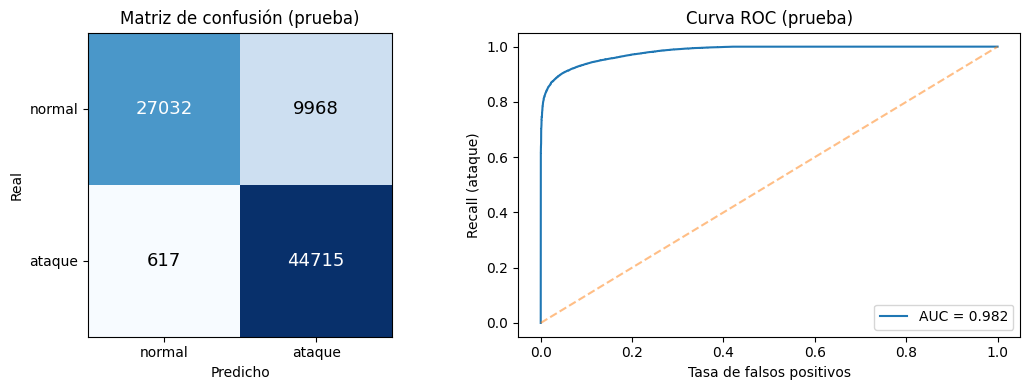

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(m, cmap="Blues")
for (i, j), v in np.ndenumerate(m):
    ax[0].text(j, i, f"{v}", ha="center", va="center", color="white" if v > m.max()/2 else "black", fontsize=13)
ax[0].set_xticks([0, 1], ["normal", "ataque"]); ax[0].set_yticks([0, 1], ["normal", "ataque"])
ax[0].set_xlabel("Predicho"); ax[0].set_ylabel("Real"); ax[0].set_title("Matriz de confusión (prueba)")
fpr, tpr, _ = roc_curve(y_te, proba)
ax[1].plot(fpr, tpr, label=f"AUC = {resultados_prueba['ROC-AUC']:.3f}"); ax[1].plot([0, 1], [0, 1], "--", alpha=.5)
ax[1].set_xlabel("Tasa de falsos positivos"); ax[1].set_ylabel("Recall (ataque)"); ax[1].set_title("Curva ROC (prueba)"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{DIR_REPORTES}/fig_prueba_matriz_roc.png", dpi=150); plt.show()

## 5. Análisis de errores

Proporción de registros marcados como ataque, por categoría real
(en 'Normal' esa proporción son los falsos positivos; en las demás es el recall)

                registros  detectados_como_ataque  proporcion_marcada_ataque
categoria                                                                   
Normal              37000                    9968                      0.269
Generic             18871                   18869                      1.000
Exploits            11132                   11092                      0.996
Fuzzers              6062                    5496                      0.907
DoS                  4089                    4086                      0.999
Reconnaissance       3496                    3495                      1.000
Analysis              677                     675                      0.997
Backdoor              583                     583                      1.000
Shellcode             378                     375                      0.992
Worms 

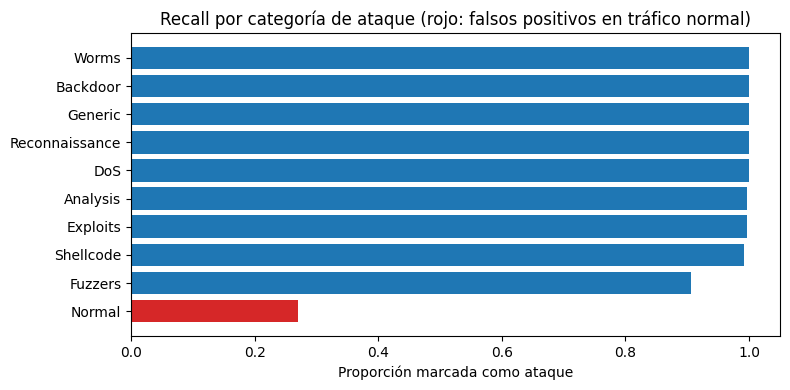

In [7]:
# 5.1 ¿Qué ataques se escapan? Recall por categoría de ataque (falsos negativos)
dfe = pd.DataFrame({"categoria": cat_te.values, "real": y_te.values, "pred": pred, "proba": proba})
por_cat = (dfe.groupby("categoria")
           .agg(registros=("real", "size"), detectados_como_ataque=("pred", "sum"))
           .assign(proporcion_marcada_ataque=lambda d: d["detectados_como_ataque"] / d["registros"])
           .sort_values("registros", ascending=False))
print("Proporción de registros marcados como ataque, por categoría real")
print("(en 'Normal' esa proporción son los falsos positivos; en las demás es el recall)\n")
print(por_cat.round(3))
por_cat.round(4).to_csv(f"{DIR_REPORTES}/errores_por_categoria.csv")

fig, ax = plt.subplots(figsize=(8, 4))
p = por_cat["proporcion_marcada_ataque"].sort_values()
ax.barh(p.index, p.values, color=["#d62728" if c == "Normal" else "#1f77b4" for c in p.index])
ax.set_xlabel("Proporción marcada como ataque"); ax.set_title("Recall por categoría de ataque (rojo: falsos positivos en tráfico normal)")
plt.tight_layout(); plt.savefig(f"{DIR_REPORTES}/fig_errores_por_categoria.png", dpi=150); plt.show()

In [8]:
# 5.2 ¿Dónde se concentran los errores? (protocolo y servicio)
fn_mask = (y_te.values == 1) & (pred == 0)
fp_mask = (y_te.values == 0) & (pred == 1)
for col in ["service", "proto"]:
    print(f"--- {col}: falsos negativos (ataques no detectados) ---")
    print(X_te.loc[fn_mask, col].value_counts().head(5).to_string())
    print(f"--- {col}: falsos positivos (normal marcado como ataque) ---")
    print(X_te.loc[fp_mask, col].value_counts().head(5).to_string(), "\n")

--- service: falsos negativos (ataques no detectados) ---
service
-       569
ftp      29
http     19
--- service: falsos positivos (normal marcado como ataque) ---
service
-         8464
http      1196
ftp        305
radius       2
dns          1 

--- proto: falsos negativos (ataques no detectados) ---
proto
tcp    466
udp    151
--- proto: falsos positivos (normal marcado como ataque) ---
proto
tcp     7071
udp     2892
igmp       5 



## 6. Confianza de la predicción (insumo para la Persona B)
Distribución de `predict_proba` según el pipeline acierte o falle. Si los errores se concentran cerca de 0,5, esa zona justifica una alerta de confianza "baja". **Los umbrales definitivos los define la Persona B; no los ajustes mirando la prueba.**

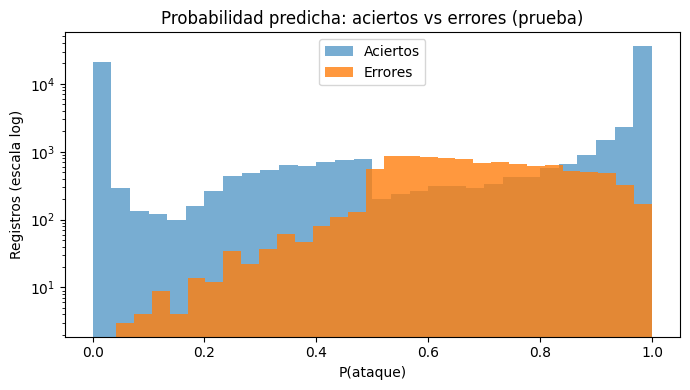

               registros  tasa_error
proba                               
(-0.001, 0.2]      21816       0.002
(0.2, 0.4]          3219       0.072
(0.4, 0.6]          5960       0.502
(0.6, 0.8]          6636       0.683
(0.8, 1.0]         44701       0.063


In [9]:
dfe["acierto"] = (dfe["real"] == dfe["pred"])
plt.figure(figsize=(7, 4))
plt.hist(dfe.loc[dfe["acierto"], "proba"], bins=30, alpha=.6, label="Aciertos")
plt.hist(dfe.loc[~dfe["acierto"], "proba"], bins=30, alpha=.8, label="Errores")
plt.yscale("log"); plt.xlabel("P(ataque)"); plt.ylabel("Registros (escala log)"); plt.legend()
plt.title("Probabilidad predicha: aciertos vs errores (prueba)")
plt.tight_layout(); plt.savefig(f"{DIR_REPORTES}/fig_confianza_prueba.png", dpi=150); plt.show()

bins = pd.cut(dfe["proba"], [0, .2, .4, .6, .8, 1.0], include_lowest=True)
print(dfe.groupby(bins, observed=True).agg(registros=("acierto", "size"), tasa_error=("acierto", lambda s: 1 - s.mean())).round(3))

## 7. Variables más importantes

sttl              0.2509
ct_state_ttl      0.1998
dttl              0.0600
dload             0.0449
ct_dst_src_ltm    0.0357
ct_srv_dst        0.0352
ackdat            0.0340
tcprtt            0.0318
rate              0.0307
sbytes            0.0228
dtype: float64


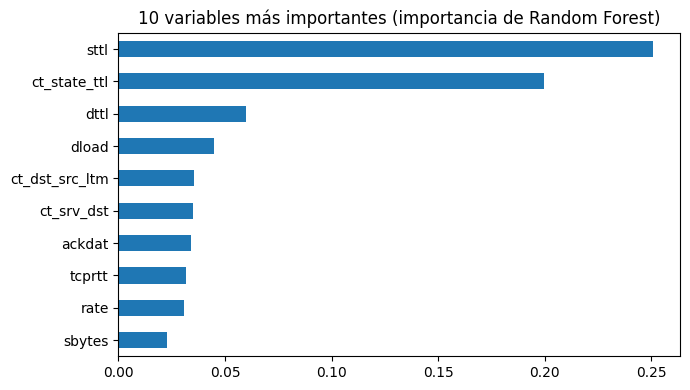

In [10]:
nombres = pipeline_final.named_steps["pre"].get_feature_names_out()
imp = pd.Series(pipeline_final.named_steps["modelo"].feature_importances_, index=nombres).sort_values(ascending=False)
print(imp.head(10).round(4))
imp.head(10)[::-1].plot.barh(figsize=(7, 4), title="10 variables más importantes (importancia de Random Forest)")
plt.tight_layout(); plt.savefig(f"{DIR_REPORTES}/fig_importancia_variables.png", dpi=150); plt.show()

## 8. Por qué se descartan los otros modelos

| Modelo | F1 (CV) | Recall (CV) | ROC-AUC (CV) | Inferencia (ms/1000) | Motivo de descarte |
|---|---|---|---|---|---|
| KNN | 0,9045 ± 0,0055 | 0,918 | 0,965 | 212 | Menor F1, recall y ROC-AUC que Random Forest; su inferencia es unas 7 veces más lenta, porque compara cada registro contra todo el entrenamiento. |
| SVM | 0,9088 ± 0,0054 | 0,975 | 0,972 | 470 | Tiene el mayor recall, pero la menor precisión (0,851), lo que implica más falsas alarmas, y la inferencia más lenta (unas 15 veces la de Random Forest). |
| MLP | 0,9116 ± 0,0020 | 0,937 | 0,977 | 7,9 | F1 y ROC-AUC menores que Random Forest, mayor variabilidad del recall entre pliegues (± 0,0128) y menor interpretabilidad. |
| **Random Forest (elegido)** | 0,9253 ± 0,0033 | 0,943 | 0,983 | 12,1 | Mejor F1 y ROC-AUC, inferencia rápida y estable entre pliegues, con importancia de variables disponible para interpretar. |

**Cómo se eligió.** La selección se hizo solo con validación cruzada sobre entrenamiento; KNN, SVM y MLP no se evaluaron en el conjunto de prueba. Entre las tres configuraciones de Random Forest (inicial, algoritmo genético y búsqueda aleatoria) la diferencia de F1 fue de 0,0005 a 0,0008, menor que la desviación entre pliegues, por lo que se eligió la de menor costo de inferencia (la del algoritmo genético: 150 árboles, `max_depth=20`, `max_features=0.3`).

**Compromiso reconocido.** El SVM obtuvo un recall de ataque mayor (0,975 frente a 0,943). Se descartó porque su precisión es la más baja de los cuatro modelos y su inferencia es unas 15 veces más lenta; ajustar el umbral de decisión de Random Forest es una vía para subir el recall sin ese costo.

**Limitación de comparabilidad.** Las cifras de KNN, SVM y MLP provienen de `02_modelos` (Google Colab, scikit-learn 1.6.1); las de Random Forest provienen de `03_optimizacion_ga`, ejecutado en otro equipo con otras versiones de las librerías (scikit-learn 1.9.1). Las diferencias entre entornos son del orden de 0,0015 de F1, pequeñas frente a la ventaja de Random Forest sobre los otros tres modelos, pero deben declararse. El tiempo de inferencia de Random Forest (12,1 ms por 1000 registros) se midió en Colab sobre la prueba.
## 9. Notas para el informe

**Resultado en prueba** (una sola evaluación, conjunto oficial de 82 332 registros): F1 = 0,894, precisión = 0,818, recall = 0,986, ROC-AUC = 0,982, exactitud = 0,871. Matriz de confusión: 27 032 verdaderos negativos, 9 968 falsos positivos, 617 falsos negativos y 44 715 verdaderos positivos.

**Comparación con la validación cruzada.** El F1 bajó de 0,925 a 0,894 y la precisión de 0,908 a 0,818, mientras el recall subió de 0,943 a 0,986. El ROC-AUC se mantuvo (0,983 frente a 0,982), lo que indica que la capacidad de discriminación se conserva y que el punto de corte de 0,5 es el menos adecuado para la prueba: el modelo detecta casi todos los ataques a costa de marcar como ataque el 27 % del tráfico normal. Ni la mayor proporción de ataques en la prueba (55,1 % frente a 48,8 %) ni el solapamiento con entrenamiento (10,4 %) explican esa caída de precisión; la causa más probable es que el tráfico normal de la prueba difiere del de entrenamiento, pero no se comprobó.

**Análisis de errores.**
- Falsos negativos (617): el 92 % son Fuzzers (566 de 6 062; recall 0,907). El resto de categorías supera 0,99, y Reconnaissance, Backdoor y Worms alcanzan el 100 %. El 92 % de los ataques no detectados tiene `service` igual a `-`.
- Falsos positivos (9 968): el 85 % corresponde a flujos con `service` igual a `-`, y 7 071 usan TCP.
- Confianza: cerca del 70 % de los errores se concentra entre P(ataque) de 0,4 y 0,8 (15 % de los registros); con P ≤ 0,2 la tasa de error es 0,2 %.
- Variables: `sttl`, `ct_state_ttl` y `dttl` concentran cerca de la mitad de la importancia (0,25, 0,20 y 0,06), lo que sugiere sensibilidad a rasgos del entorno de simulación. Es una hipótesis que requiere un experimento sin esas variables.

**Límites.**
- Dataset sintético, generado en laboratorio en 2015: no refleja necesariamente las amenazas actuales.
- Los tipos de ataque están muy desbalanceados (Exploits y Fuzzers dominan; Worms, Backdoor y Analysis tienen muy pocos registros), por lo que el recall por categoría es inestable en las raras.
- La prueba conserva sus duplicados (32 %), y el 10,4 % de sus registros también aparece en entrenamiento.
- La optimización con algoritmo genético mejoró el F1 dentro del ruido (0,0005 a 0,0008), con una sola semilla y una sola ejecución por método.
- La validación cruzada y la optimización usaron una submuestra de 25 000 registros, pero el modelo final se entrenó con los 101 269 sin duplicados, por lo que las cifras de CV no corresponden exactamente a ese modelo.
- Los experimentos se corrieron en dos entornos distintos (Colab y otro equipo con otras versiones de scikit-learn).
- Se usó el umbral por defecto de 0,5; ajustarlo, con validación cruzada sobre entrenamiento, es una mejora futura para reducir falsos positivos.
- El modelo no sustituye a un sistema de seguridad en producción.